# Notebook 1: Interactive SED Model — MG3 J163554+3629

**Purpose:** Manually set jet and electron distribution parameters and immediately see the resulting SED. Useful for building physical intuition before running any fitter.

Load the pipeline prefit model, override any parameters you want, evaluate, and plot.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import dill
%matplotlib inline

from jetset.data_loader import Data, ObsData

# Load the saved prefit model from the pipeline notebook
# Run 00_basic_pipeline.ipynb first to generate these files
fit_model = dill.load(open('../../results/models/prefit_model.pkl', 'rb'))

# Load processed SED data
sed_data = ObsData.load('../../results/models/sed_data_unbinned.pkl')

print('Model loaded successfully.')
fit_model.show_model()

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open)) * R_H
Model loaded successfully.

--------------------------------------------------------------------------------
Composite model description
--------------------------------------------------------------------------------
name: Final_Fit  
type: composite_model  
components models:
 -model name: jet_leptonic model type: jet
 -model name: Franceschini_2008 model type: table2D

--------------------------------------------------------

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.937958e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,2.686264e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.717180e+03,0.000000e+00,--,False,False
jet_leptonic,gamma_break,turn-over-energy,lorentz-factor*,4.193407e+03,1.000000e+00,1.000000e+09,False,False
jet_leptonic,p,LE_spectral_slope,,2.221260e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,p_1,HE_spectral_slope,,3.500000e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,T_DT,DT,K,8.819000e+02,0.000000e+00,--,False,False
jet_leptonic,"*R_DT(D,L_Disk)",DT,cm,2.350915e+19,0.000000e+00,--,False,True
jet_leptonic,tau_DT,DT,,1.000000e-01,0.000000e+00,1.000000e+00,False,False
jet_leptonic,R_inner_Sw,Disk,Sw. radii*,3.000000e+00,0.000000e+00,--,False,False


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description
--------------------------------------------------------------------------------
name: Franceschini_2008  
type: table2D  

--------------------------------------------------------------------------------


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
Franceschini_2008,scale_factor,scale_factor,,1.000000e+00,0.000000e+00,--,False,True
Franceschini_2008,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------


---
## Parameters to tweak

Edit the values in the cell below and re-run it + the plot cell to see the effect immediately.

### Electron distribution
| Parameter | Physical meaning |
|-----------|------------------|
| `N` | Normalisation — total number of emitting electrons |
| `p` | Spectral index below the break (harder = smaller p) |
| `p_1` | Spectral index above the break (softer = larger p_1) |
| `gamma_break` | Break Lorentz factor — transition energy between p and p_1 |
| `gmin` | Minimum Lorentz factor of the electron distribution |
| `gmax` | Maximum Lorentz factor |

### Jet geometry & magnetic field
| Parameter | Physical meaning |
|-----------|------------------|
| `B` | Magnetic field strength in the jet (Gauss) |
| `BulkFactor` | Bulk Lorentz factor Γ of the jet |
| `R_H` | Distance of emission region from the black hole (cm) |

### Central engine
| Parameter | Physical meaning |
|-----------|------------------|
| `M_BH` | Black hole mass (solar masses) |
| `L_Disk` | Accretion disk luminosity (erg/s) |
| `accr_eff` | Radiative efficiency η (L_Disk = η × Ṁ c²) |
| `T_DT` | Dust torus temperature (K) — controls peak of DT seed photons |

In [32]:
# ============================================================
# EDIT PARAMETERS HERE
# ============================================================

# --- Electron distribution ---
fit_model.jet_leptonic.parameters.N.val           = 2000.0    # electron normalisation
fit_model.jet_leptonic.parameters.p.val           = 1.590     # low-energy spectral index
fit_model.jet_leptonic.parameters.p_1.val         = 3.066     # high-energy spectral index
fit_model.jet_leptonic.parameters.gamma_break.val = 381.0     # break Lorentz factor
fit_model.jet_leptonic.parameters.gmin.val        = 2.1       # minimum Lorentz factor
fit_model.jet_leptonic.parameters.gmax.val        = 1.653e4   # maximum Lorentz factor

# --- Jet geometry & B field ---
fit_model.jet_leptonic.parameters.B.val           = 0.0555    # Gauss
fit_model.jet_leptonic.parameters.BulkFactor.val  = 16.76     # bulk Lorentz factor
fit_model.jet_leptonic.parameters.R_H.val         = 1.602e18  # cm

# --- Central engine ---
fit_model.jet_leptonic.parameters.M_BH.val        = 1.56e9   # solar masses
fit_model.jet_leptonic.parameters.L_Disk.val      = 1.435e46  # erg/s
fit_model.jet_leptonic.parameters.accr_eff.val    = 0.083     # radiative efficiency
fit_model.jet_leptonic.parameters.T_DT.val        = 617.6     # K
fit_model.jet_leptonic.parameters.R_inner_Sw.val  = 7.27      # inner disk radius (Schwarzschild units)
fit_model.jet_leptonic.parameters.R_ext_Sw.val    = 4892.6    # outer disk radius (Schwarzschild units)

# Evaluate model with new parameters
fit_model.eval()

# Derived quantities
delta   = fit_model.jet_leptonic.get_beaming()
L_Edd   = 1.26e38 * fit_model.jet_leptonic.parameters.M_BH.val
lambda_Edd = fit_model.jet_leptonic.parameters.L_Disk.val / L_Edd

print(f'Beaming factor δ  : {delta:.3f}')
print(f'Eddington ratio   : {lambda_Edd:.4f}')
print(f'L_Edd             : {L_Edd:.3e} erg/s')

Beaming factor δ  : 18.944
Eddington ratio   : 0.0730
L_Edd             : 1.966e+47 erg/s


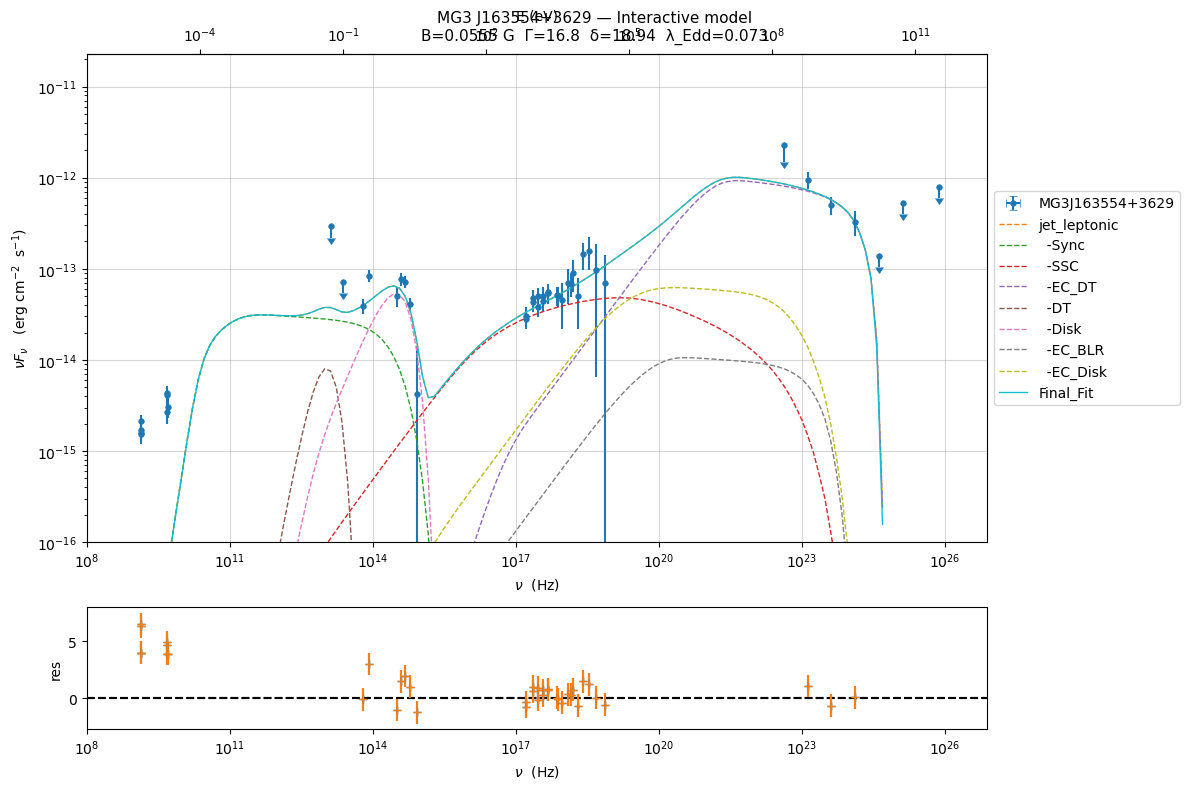

In [33]:
# ============================================================
# PLOT — re-run this cell after changing parameters above
# ============================================================


p = fit_model.plot_model(sed_data=sed_data)
p.add_residual_plot(fit_model, sed_data)
p.setlim(y_min=1E-16, x_min=1E8)
plt.suptitle(
    f'MG3 J163554+3629 — Interactive model\n'
    f'B={fit_model.jet_leptonic.parameters.B.val:.4f} G  '
    f'Γ={fit_model.jet_leptonic.parameters.BulkFactor.val:.1f}  '
    f'δ={delta:.2f}  '
    f'λ_Edd={lambda_Edd:.3f}',
    fontsize=11
)
plt.show()

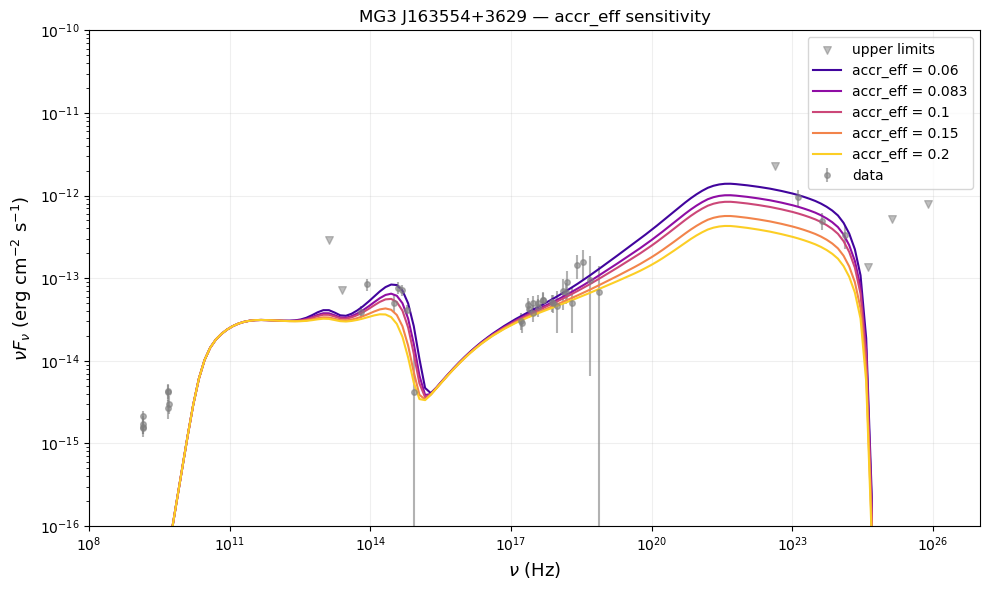

In [39]:
# ============================================================
# PARAMETER SENSITIVITY — vary one parameter, overlay SEDs
# ============================================================
# Useful for seeing how strongly each parameter affects the SED shape.
# Change 'param_name' and 'values' to explore.

param_name = 'accr_eff'                          # parameter to vary
values     = [0.06, 0.083, 0.10, 0.15, 0.20]  # values to try
colors     = plt.cm.plasma(np.linspace(0.1, 0.9, len(values)))

# Widen boundaries first (ACC EFF in this case)
fit_model.jet_leptonic.parameters.accr_eff.val_min = 0.05
fit_model.jet_leptonic.parameters.accr_eff.val_max = 0.40

param_name = 'accr_eff'                          
values     = [0.06, 0.083, 0.10, 0.15, 0.20]

fig, ax = plt.subplots(figsize=(10, 6))

# Plot data
mask_ul  = sed_data.table['UL'].astype(bool)
mask_det = ~mask_ul
ax.errorbar(
    sed_data.table['nu_data'][mask_det],
    sed_data.table['nuFnu_data'][mask_det],
    yerr=sed_data.table['dnuFnu_data'][mask_det],
    fmt='o', color='gray', ms=4, alpha=0.6, label='data'
)
ax.scatter(
    sed_data.table['nu_data'][mask_ul],
    sed_data.table['nuFnu_data'][mask_ul],
    marker='v', color='gray', s=30, alpha=0.5, label='upper limits'
)

# Overlay model curves
for val, col in zip(values, colors):
    fit_model.jet_leptonic.set_par(param_name, val=val)
    fit_model.eval()
    nu   = fit_model.SED.nu.value
    flux = fit_model.SED.nuFnu.value
    good = np.isfinite(flux) & (flux > 0) & np.isfinite(nu)
    ax.loglog(nu[good], flux[good], color=col, lw=1.5,
              label=f'{param_name} = {val}')

ax.set_xlim(1e8, 1e27)
ax.set_ylim(1e-16, 1e-10)
ax.set_xlabel(r'$\nu$ (Hz)', fontsize=13)
ax.set_ylabel(r'$\nu F_\nu$ (erg cm$^{-2}$ s$^{-1}$)', fontsize=13)
ax.set_title(f'MG3 J163554+3629 — {param_name} sensitivity', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# Reset to best-fit values after sensitivity scan (Important step)
fit_model.jet_leptonic.parameters.accr_eff.val = 0.0555
fit_model.eval()